# Latent-factor enrichment — B cell (male donor)

Same analysis as the original `03_lf_enrich.ipynb`, but driven through the
`focal.state_specific` backend instead of ~250 lines of notebook-local functions.

| original notebook | backend call |
| --- | --- |
| `fetch_GRN_data` | `sse.load_grn_data()` |
| `read_slide_data` | `sse.load_slide_features_combined(...)` |
| `create_combined_links_for_cluster_fusion` + `filter_combined_links_and_build_grn` | inside `sse.run_enrichment()` |
| `get_SLIDE_GRN_enrichment` | inside `sse.run_enrichment()` |
| `create_enrichment_df` + pickle dump | inside `sse.run_enrichment()` |
| *(not in the original)* | `sse.plot_enrichment_scores_with_color_proportions(...)` |

**Input**  SLIDE LF feature lists + the CellOracle oracle object
**Output** TF-enrichment barplots, plus the enrichment tables and pickles the
original wrote.

## Housekeeping

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from focal.state_specific import StateSpecificEnrichment
from focal.state_specific._enrichment import plot_tf_enrichment_bars

%config InlineBackend.figure_format = 'retina'
%matplotlib inline
plt.rcParams['figure.figsize'] = [6, 4.5]
plt.rcParams['savefig.dpi'] = 300

## Inputs

`load_grn_data()` reads `<grn_workdir>/out_files/<oracle_object_name>` and
`<grn_workdir>/out_files/ridge_fitted_2_merged_network_scores.csv`, so
`GRN_WORKDIR` below is a directory whose `out_files` holds both. The CellOracle
object is ~2.8 GB and takes a few minutes to load.

In [2]:
GRN_WORKDIR = Path('/work/hdd/bhdw/afu2/male_donor/lf_enrich_backend')
ORACLE_NAME = 'oracle_fitted.celloracle.oracle'
SLIDE_ROOT  = Path('/work/hdd/bhdw/asachan/male_donor/out_data/out_other_methods/SLIDE_Runs')
OUT_PATH    = Path('/work/hdd/bhdw/afu2/male_donor/out_data/lf_enrich')

assert (GRN_WORKDIR / 'out_files' / ORACLE_NAME).exists()
assert (GRN_WORKDIR / 'out_files' / 'ridge_fitted_2_merged_network_scores.csv').exists()

### Experiment parameters

Unchanged from the original notebook's `input_dict`. `slide_starting_genes` is the
SLIDE universe size `P` in the hypergeometric test, so it is per-experiment.

Note the barplot path needs `order_fr_tfcomb = [1]`: `tf_enrichment_scores()`
scores single TFs and raises for higher orders, where the records describe TF
*combinations* rather than individual TFs.

In [3]:
# Cluster ids are strings in oracle.coef_matrix_per_cluster ('0'..'11'), so they
# are quoted here exactly as the original notebook had them.
INPUTS = pd.DataFrame({
    'experiment':           ['PRDM1_KO', 'IRF4_KO', 'GC_PB', 'PB_ABC', 'GC_ABC'],
    'slide_starting_genes': [4472, 4500, 4725, 3420, 4603],
    'clusters_of_interest': [['3', '7'], ['3', '7'], ['7', '3'], ['1', '7'], ['1', '3']],
    'order_fr_clust':       [[2], [2], [2], [2], [2]],
    'order_fr_tfcomb':      [[1], [1], [2], [2], [2]],
}).set_index('experiment')
INPUTS

,slide_starting_genes,clusters_of_interest,order_fr_clust,order_fr_tfcomb
experiment,,,,
PRDM1_KO,4472,"[3, 7]",[2],[1]
IRF4_KO,4500,"[3, 7]",[2],[1]
GC_PB,4725,"[7, 3]",[2],[2]
PB_ABC,3420,"[1, 7]",[2],[2]
GC_ABC,4603,"[1, 3]",[2],[2]


In [4]:
EXPERIMENT = 'IRF4_KO'
params = INPUTS.loc[EXPERIMENT]

# For IRF4_KO the original notebook keeps only two latent factors, Z4 and Z36.
# It selects them with `'Z4' in file or 'Z36' in file`, and because "Z46"
# contains "Z4" that substring test also pulls in feature_list_Z46.txt -- three
# LFs rather than two. Matching the LF name exactly is almost certainly what was
# meant; set INCLUDE_Z46 = True to reproduce the original's gene set.
LF_KEEP     = {'IRF4_KO': ['Z4', 'Z36']}
INCLUDE_Z46 = False

lf_files = sorted(SLIDE_ROOT.glob(f'{EXPERIMENT}/*/*feature_list*'))
if EXPERIMENT in LF_KEEP:
    keep = set(LF_KEEP[EXPERIMENT]) | ({'Z46'} if INCLUDE_Z46 else set())
    lf_files = [f for f in lf_files if f.stem.split('_')[-1] in keep]

for f in lf_files:
    print(f.relative_to(SLIDE_ROOT))

IRF4_KO/0.05_1_out/feature_list_Z36.txt
IRF4_KO/0.05_1_out/feature_list_Z4.txt


## 1. Instantiate the backend

In [5]:
sse = StateSpecificEnrichment(
    grn_workdir=GRN_WORKDIR,
    oracle_object_name=ORACLE_NAME,
    feature_folder=SLIDE_ROOT / EXPERIMENT,
    out_path=OUT_PATH,
    slide_starting_genes=int(params['slide_starting_genes']),
    clusters_of_interest=params['clusters_of_interest'],
    order_fr_clust=params['order_fr_clust'],
    order_fr_tfcomb=params['order_fr_tfcomb'],
    quantile=0.90,
    experiment_label=EXPERIMENT,
)
sse.out_path

PosixPath('/work/hdd/bhdw/afu2/male_donor/out_data/lf_enrich')

## 2. Load the inputs

`load_slide_features_combined(keep_corr_sign=True)` fuses the LF gene lists into one
cellular program *and* records each gene's correlation sign. The signs are what
colour the bars later, so the plain `load_slide_features_from_files()` would run
the enrichment fine but leave the barplot unavailable.

In [6]:
sse.load_grn_data()
print(f'clusters in the oracle : {sorted(sse.GRN_links_after_fit)}')
print(f'GRN TFs                : {len(sse.GRN_TFs):,}')
print(f'network scores         : {sse.GRN_network_scores.shape}')

which: no R in (/u/afu2/.vscode-server/cli/servers/Stable-2c33b50b16c472efe58357d1d2a8a5414bc23fbf/server/bin/remote-cli:/sw/rh9.4/python/miniforge3/bin:/sw/rh9.4/python/miniforge3/condabin:/u/afu2/.local/bin:/u/afu2/bin:/opt/nvidia/hpc_sdk/Linux_x86_64/26.5/cuda/13.2/compute-sanitizer:/opt/nvidia/hpc_sdk/Linux_x86_64/26.5/cuda/13.2/bin:/opt/nvidia/hpc_sdk/Linux_x86_64/26.5/cuda/13.2/libnvvp:/opt/nvidia/hpc_sdk/Linux_x86_64/26.5/profilers/Nsight_Compute:/opt/nvidia/hpc_sdk/Linux_x86_64/26.5/profilers/Nsight_Systems/bin:/opt/cray/pe/mpich/9.1.0/ofi/gnu/11.2/bin:/opt/cray/pe/mpich/9.1.0/bin:/opt/cray/pe/craype/2.7.36/bin:/opt/rh/gcc-toolset-14/root/usr/bin:/opt/cray/libfabric/2.3.1/bin:/sw/rh9.4/user/scripts:/sw/user/scripts:/usr/local/bin:/usr/bin:/usr/local/sbin:/usr/sbin:/opt/puppetlabs/bin:/opt/cray/pe/bin:/u/afu2/.vscode-server/extensions/ms-python.debugpy-2026.6.0-linux-x64/bundled/scripts/noConfigScripts:/u/afu2/.vscode-server/data/User/globalStorage/github.copilot-chat/debugComma

/u/afu2/.conda/envs/celloracle_env/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


clusters in the oracle : ['0', '1', '10', '11', '2', '3', '4', '5', '6', '7', '8', '9']
GRN TFs                : 1,485
network scores         : (16979, 9)


In [7]:
sse.load_slide_features_combined(lf_files, keep_corr_sign=True)
print(f'SLIDE genes (union)    : {len(sse.slide_features):,}')
print(f'  positively correlated: {len(sse.positive_corr_names):,}')
print(f'  negatively correlated: {len(sse.negative_corr_names):,}')

Combined CP: 59 unique genes from 2 LFs
  feature_list_Z36.txt                        39 genes  (no threshold)
  feature_list_Z4.txt                         39 genes  (no threshold)
sign_resolution='majority': 34 positive, 25 negative, 0 genes with conflicting signs across LFs
SLIDE genes (union)    : 59
  positively correlated: 34
  negatively correlated: 25


## 3. Run the enrichment

One call replaces the original notebook's nested loop. It fuses the clusters,
thresholds edges at `quantile`, widens the TF candidate set through the graph,
scores every TF combination and strength condition, then writes the enrichment
table and the `cc_dict` pickle per fusion.

In [8]:
sse.run_enrichment(save_pickle=True, show_progress=True)

fusion = sse.cluster_fusions[0]
ord_tf = params['order_fr_tfcomb'][0]
print(f'fusions  : {sse.cluster_fusions}')
print(f'records  : {len(sse._records(fusion, ord_tf)):,}')

# The `dfs` column holds tuples of DataFrames. Rendering a DataFrame nested
# inside a cell raises StopIteration in pandas' pretty-printer (it sizes the
# sequence with len(df), the row count, but iterates it, which yields column
# names), so drop that column for display.
sse.enrichment_dfs[fusion][ord_tf].drop(columns=['dfs']).head()

SLIDE–GRN enrichment ('3', '7'):   0%|          | 0/61 [00:00<?, ?it/s]

fusions  : [('3', '7')]
records  : 122


,TF,condition,case,score,p_value,common,dwnstrm
0,"(HIVEP1,)","(1,)",slide,5.135709,0.001382,"[SLC23A2, SMAP2]","[ACOXL, ALG13, CCDC88A, CHST15, DUSP4, GRK3, H..."
1,"(NFATC2,)","(1,)",slide,3.311281,0.003050,"[INO80, NCK1, EVL]","[ADPGK, AGPAT5, AHR, ANK2, ANO10, ARHGAP17, AT..."


## 4. Post-process

`build_used_weight_df` flattens the per-record deduplicated edge tables into one
CSV; `build_slide_lf_enriched` explodes the enriched TF→target links and joins the
strong-edge weights onto them. The barplot needs the second one.

In [9]:
used_weights = sse.build_used_weight_df(fusion, ord_tf)
slide_lf     = sse.build_slide_lf_enriched(fusion, ord_tf)
print(f'used_weights : {used_weights.shape}')
print(f'slide_lf     : {slide_lf.shape}')
slide_lf.head()

used_weights : (12768, 7)
slide_lf     : (5, 7)


,source,target,key,weight,cluster,strength,case
0,HIVEP1,SLC23A2,1,0.212082,7,1,slide
1,HIVEP1,SMAP2,0,0.226704,7,1,slide
2,NFATC2,INO80,0,0.258953,3,1,slide
3,NFATC2,NCK1,0,0.248492,3,1,slide
4,NFATC2,EVL,0,0.223973,7,1,slide


## 5. TF enrichment barplots

Bar height is the TF's enrichment score. The red/blue/grey split is the share of
that TF's downstream targets that are positively correlated LF genes, negatively
correlated ones, or not LF genes at all.

`sse.plot_enrichment_scores_with_color_proportions()` is the one-call version, but
it ends in `fig.write_image(..., format='svg')`, and plotly's kaleido v1 backend
shells out to Chrome, which is not installed on the Delta login nodes. The cells
below therefore use the same two helpers that method calls internally —
`build_tf_color_bar_table` for the table, then either renderer — so the figure is
produced without the SVG round-trip.

In [10]:
# Every candidate TF gets a score; only those passing the order-1 filter
# (p < 0.05, >2 downstream genes, >1 shared gene, score > 0) reach the
# enrichment table, and only those appear in the barplot.
scores = sse.tf_enrichment_scores(fusion, ord_tf)
print(f'{len(scores)} TFs scored')
print(f'{len(sse.enrichment_dfs[fusion][ord_tf])} passed the filter')
pd.Series(scores).sort_values(ascending=False).head(15)

61 TFs scored
2 passed the filter


HIVEP1     5.135709
HERPUD1    3.743392
PAX5       3.676278
NFATC2     3.311281
TFEC       2.643856
ARID5B     2.354350
CREB3L2    2.058894
HIVEP2     1.965784
POLR2A     1.868923
PTEN       0.936037
BCL6       0.000000
TFDP2      0.000000
PLAGL1     0.000000
REL        0.000000
RFX3       0.000000
dtype: float64

In [11]:
from focal.state_specific._enrichment import build_tf_color_bar_table

gene_colors = {**{g: 'red'  for g in sse.positive_corr_names},
               **{g: 'blue' for g in sse.negative_corr_names}}

plot_df = build_tf_color_bar_table(
    slide_lf[['source', 'target']],
    pd.DataFrame({'TF': list(scores), 'score': list(scores.values())}),
    gene_colors,
)
plot_df.head()

,source,color,proportion,height,text
0,HIVEP1,blue,0.000000,0.000000,0.0%
1,HIVEP1,gray,0.000000,0.000000,0.0%
2,HIVEP1,red,1.000000,5.135709,100.0%
3,NFATC2,blue,0.666667,2.207521,66.7%
4,NFATC2,gray,0.000000,0.000000,0.0%


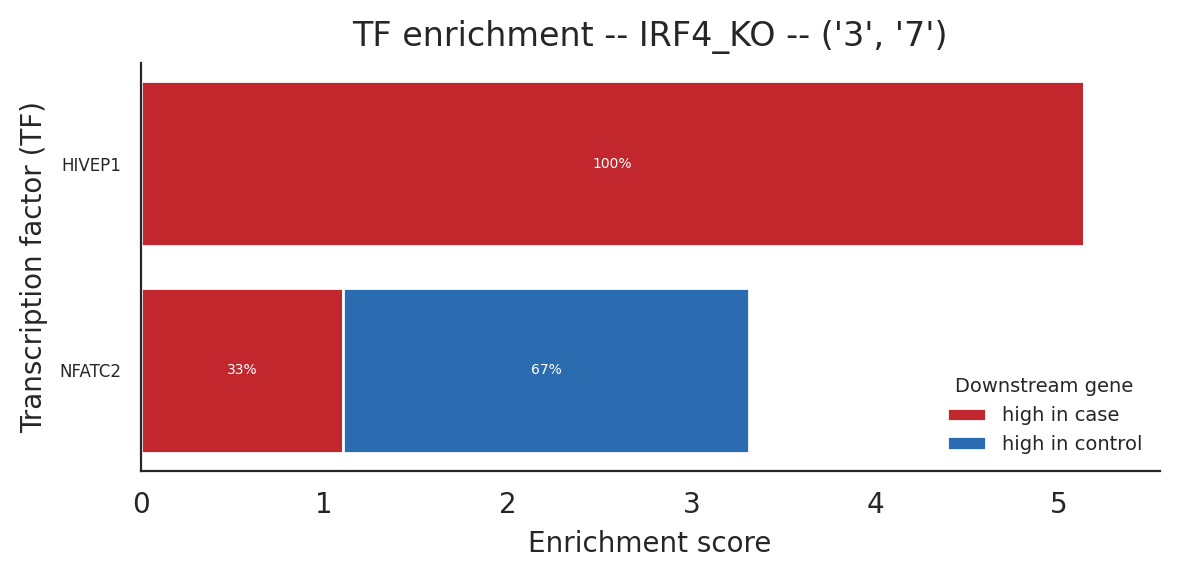

In [12]:
# Matplotlib renderer -- writes a vector PDF, no browser needed.
fig, ax = plot_tf_enrichment_bars(
    plot_df,
    title=f'TF enrichment -- {EXPERIMENT} -- {fusion}',
    out_path=OUT_PATH / 'figures' / f'tf_enrichment_bars_{EXPERIMENT}_{fusion}.pdf',
)
fig

In [13]:
# Interactive plotly renderer. Displays inline; writing it to SVG needs Chrome,
# so that step is skipped here.
from focal.state_specific._enrichment import plotly_tf_enrichment_bars

plotly_tf_enrichment_bars(plot_df, f'TF enrichment -- {EXPERIMENT} -- {fusion}')

## Outputs

```
out_data/lf_enrich/
  figures/
    tf_enrichment_bars_<experiment>_<fusion>.pdf
    combined_links_cutoff_histogram_<fusion>.pdf
    combined_links_key_strength_<fusion>_<experiment>.pdf
  out_files/SLIDE_LF_enrichment/
    enriched_df_<stem>.csv
    cc_dict_<stem>.pickle
    <stem>_used_weights.csv
    enriched_df_<stem>_used_weights_strong.csv
```

`<stem>` is `<ord_tf>_TFs_<fusion>_<experiment>`.

A previous run can be restored without recomputing:

```python
sse.load_results(fusion, ord_tf)
```